In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('retail_sales_dataset.csv')

In [3]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [4]:
df.shape

(1000, 9)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [6]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [7]:
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [8]:
df['Date'] = pd.to_datetime(df['Date'])

In [9]:
df['Date'].dtype

dtype('<M8[ns]')

In [10]:
df.dtypes

Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object

In [11]:
df['Total Amount'].sum()

np.int64(456000)

In [12]:
df['Total Amount'].mean()

np.float64(456.0)

In [13]:
df.groupby('Product Category')['Total Amount'].sum()

Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64

In [14]:
df.groupby('Product Category')['Total Amount'].mean()

Product Category
Beauty         467.475570
Clothing       443.247863
Electronics    458.786550
Name: Total Amount, dtype: float64

In [15]:
df.groupby('Gender')['Total Amount'].sum()

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64

In [16]:
df.groupby('Gender')['Total Amount'].mean()

Gender
Female    456.549020
Male      455.428571
Name: Total Amount, dtype: float64

In [17]:
df.groupby(['Product Category','Gender'])['Total Amount'].sum()

Product Category  Gender
Beauty            Female    74830
                  Male      68685
Clothing          Female    81275
                  Male      74305
Electronics       Female    76735
                  Male      80170
Name: Total Amount, dtype: int64

In [18]:
bins = [17, 25, 35, 45, 55, 100]
labels = ['18-25', '26-35', '36-45', '46-55', '56+']

df['Age Group'] = pd.cut(df['Age'], bins=bins, labels=labels)

In [19]:
age_sales=df.groupby('Age Group', observed=True)['Total Amount'].sum()

In [20]:
df.groupby('Product Category')['Quantity'].sum()

Product Category
Beauty         771
Clothing       894
Electronics    849
Name: Quantity, dtype: int64

In [21]:
df.groupby('Product Category')['Price per Unit'].mean()

Product Category
Beauty         184.055375
Clothing       174.287749
Electronics    181.900585
Name: Price per Unit, dtype: float64

In [22]:
df['Date'].dt.month

0      11
1       2
2       1
3       5
4       5
       ..
995     5
996    11
997    10
998    12
999     4
Name: Date, Length: 1000, dtype: int32

In [23]:
df['Month']=df['Date'].dt.month

In [24]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Age Group,Month
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,26-35,11
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,26-35,2
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,46-55,1
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,36-45,5
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,26-35,5


In [25]:
month_sales=df.groupby('Month')['Total Amount'].sum()

In [26]:
customer_sales=df.groupby('Customer ID')['Total Amount'].sum()

In [27]:
top_customers=customer_sales.sort_values(ascending=False).head(10)

In [28]:
df[['Quantity','Total Amount']].corr()

,Quantity,Total Amount
Quantity,1.000000,0.373707
Total Amount,0.373707,1.000000


In [29]:
df[['Price per Unit','Total Amount']].corr()

,Price per Unit,Total Amount
Price per Unit,1.000000,0.851925
Total Amount,0.851925,1.000000


([<matplotlib.axis.XTick at 0x1e5bbfabb60>,
 [Text(1, 0, '1'),
  Text(2, 0, '2'),
  Text(3, 0, '3'),
  Text(4, 0, '4'),
  Text(5, 0, '5'),
  Text(6, 0, '6'),
  Text(7, 0, '7'),
  Text(8, 0, '8'),
  Text(9, 0, '9'),
  Text(10, 0, '10'),
  Text(11, 0, '11'),
  Text(12, 0, '12')])

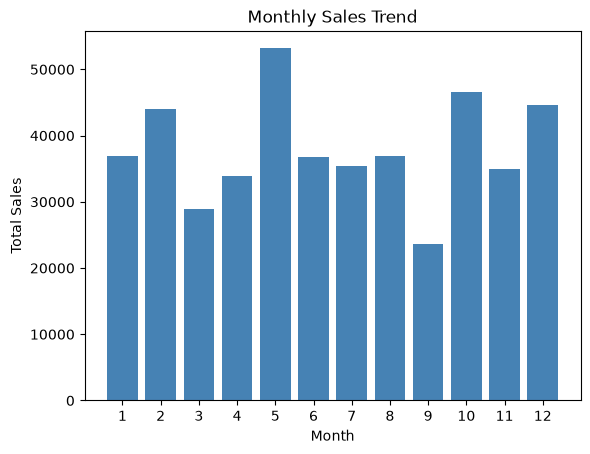

In [30]:
plt.bar(month_sales.index,month_sales.values,color='steelblue')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.title('Monthly Sales Trend')
plt.xticks(range(1, 13))

In [31]:
Product_sales=df.groupby('Product Category')['Total Amount'].sum()

Text(0.5, 1.0, 'Sales by Product Category')

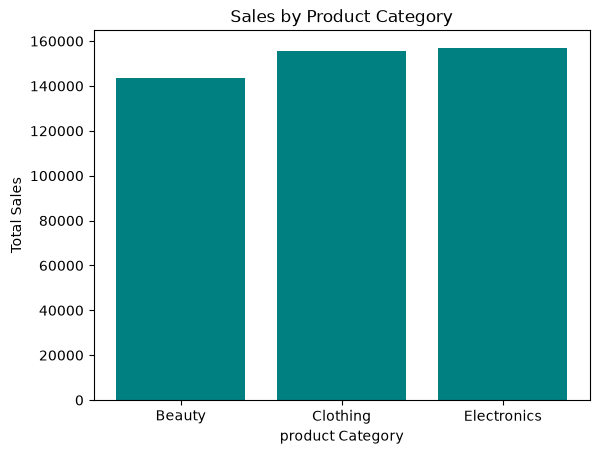

In [32]:
plt.bar(Product_sales.index,Product_sales.values,color='teal')
plt.xlabel('product Category')
plt.ylabel('Total Sales')
plt.title('Sales by Product Category')


In [33]:
gender_sales=df.groupby('Gender')["Total Amount"].sum()

Text(0.5, 1.0, 'Total Sales by Gender')

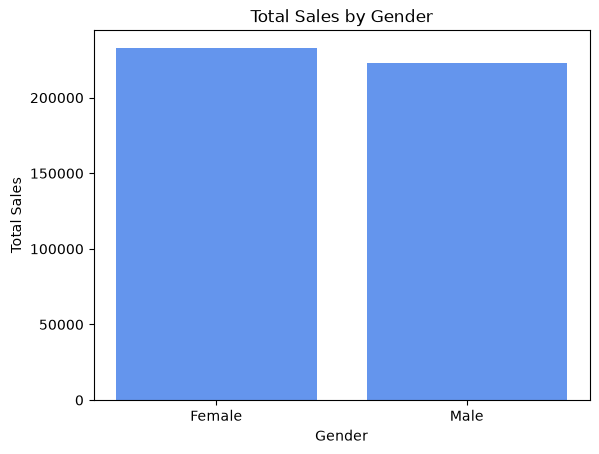

In [34]:
plt.bar(gender_sales.index,gender_sales.values,color='cornflowerblue')
plt.xlabel('Gender')
plt.ylabel('Total Sales')
plt.title("Total Sales by Gender")

Text(0.5, 1.0, 'Total Sales by Age Groups')

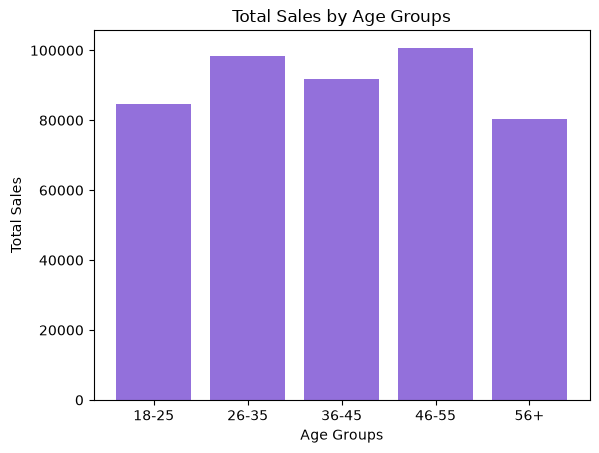

In [35]:
plt.bar(age_sales.index,age_sales.values,color='mediumpurple')
plt.xlabel("Age Groups")
plt.ylabel("Total Sales")
plt.title("Total Sales by Age Groups")

In [36]:
quantity_sold=df.groupby('Product Category')['Quantity'].sum()

Text(0.5, 1.0, 'Quantity Sold by Product Category')

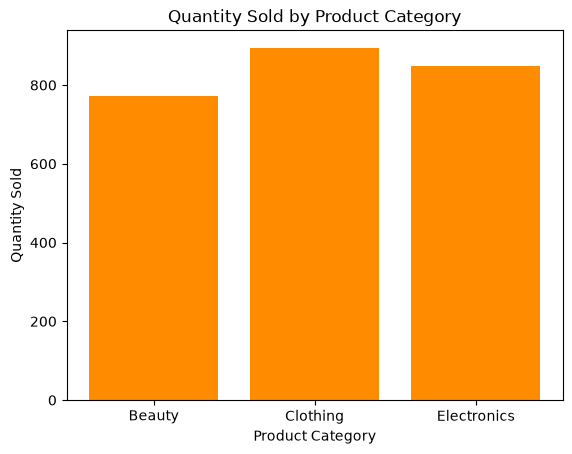

In [37]:
plt.bar(quantity_sold.index,quantity_sold.values,color='darkorange')
plt.xlabel('Product Category')
plt.ylabel('Quantity Sold')
plt.title('Quantity Sold by Product Category')

Text(0.5, 1.0, 'Total Sales by Top Customer')

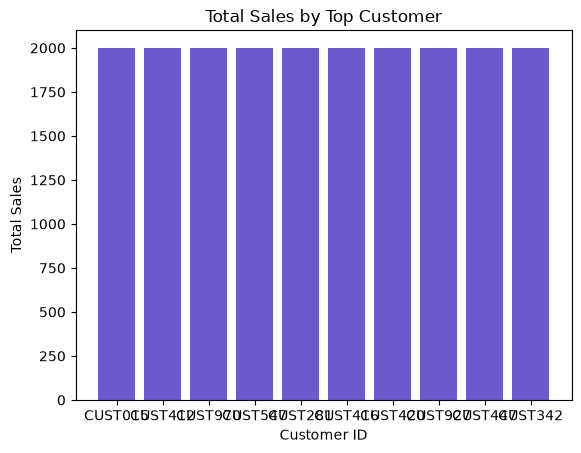

In [38]:
plt.bar(top_customers.index,top_customers.values,color='slateblue')
plt.xlabel('Customer ID')
plt.ylabel('Total Sales')
plt.title('Total Sales by Top Customer')

In [39]:
df.groupby("Customer ID")['Quantity'].count()

Customer ID
CUST001    1
CUST002    1
CUST003    1
CUST004    1
CUST005    1
          ..
CUST995    1
CUST996    1
CUST997    1
CUST998    1
CUST999    1
Name: Quantity, Length: 1000, dtype: int64

In [40]:
df.groupby(['Month','Product Category'])['Total Amount'].sum()

Month  Product Category
1      Beauty              13930
       Clothing            13125
       Electronics          9925
2      Beauty              14035
       Clothing            14560
       Electronics         15465
3      Beauty              10545
       Clothing            15065
       Electronics          3380
4      Beauty              11905
       Clothing            13940
       Electronics          8025
5      Beauty              12450
       Clothing            17455
       Electronics         23245
6      Beauty              10995
       Clothing            10170
       Electronics         15550
7      Beauty              16090
       Clothing             8250
       Electronics         11125
8      Beauty               9790
       Clothing            12455
       Electronics         14715
9      Beauty               6320
       Clothing             9975
       Electronics          7325
10     Beauty              15355
       Clothing            13315
       Electronics 

In [41]:
df.groupby('Month')['Total Amount'].mean()

Month
1     474.102564
2     518.352941
3     397.123288
4     393.837209
5     506.190476
6     476.818182
7     492.569444
8     393.191489
9     363.384615
10    485.208333
11    447.692308
12    491.098901
Name: Total Amount, dtype: float64

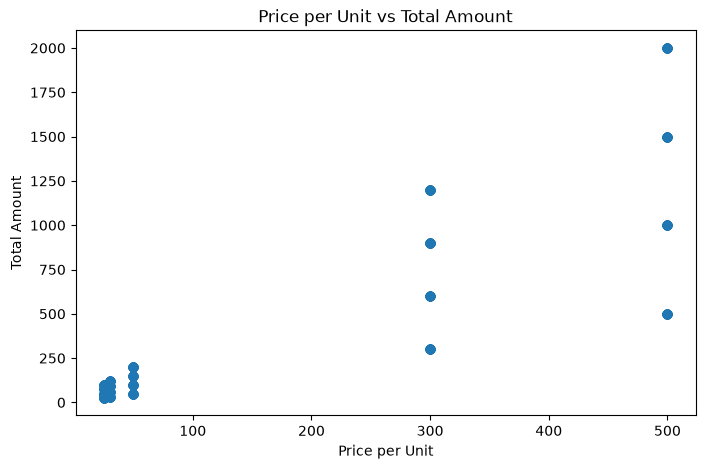

In [42]:
plt.figure(figsize=(8,5))

plt.scatter(df['Price per Unit'], df['Total Amount'])

plt.title('Price per Unit vs Total Amount')
plt.xlabel('Price per Unit')
plt.ylabel('Total Amount')

plt.show()

In [43]:
relation=df[['Quantity','Price per Unit','Total Amount']].corr()

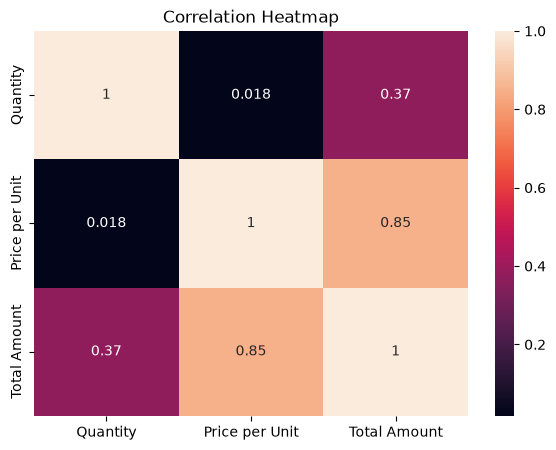

In [44]:
plt.figure(figsize=(7,5))

sns.heatmap(relation, annot=True)

plt.title('Correlation Heatmap')

plt.show()